# Sensor fusion
This notebooks seeks the prupose of combining gyroscope and accelerometer into one tilt angle, and choosing the filter constant 

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data")
SLOW = DATA / "sample" / "tilt_slow.csv"
FAST = DATA / "sample" / "tilt_fast.csv"

In [9]:
def load(path):
    df = pd.read_csv(path)
    df["t"] = (df["time_us"] - df["time_us"].iloc[0]) / 1e6
    df["dt"] = df["t"].diff().fillna(0)
    return df

slow = load(SLOW)
fast = load(FAST)

In [43]:
slow["angle_acc"]  = np.degrees(np.arctan2(slow["ax"], np.sqrt(slow["ay"]**2 + slow["az"]**2)))
rate = -slow["gy"]
bias = rate[slow["t"] < 2].mean()

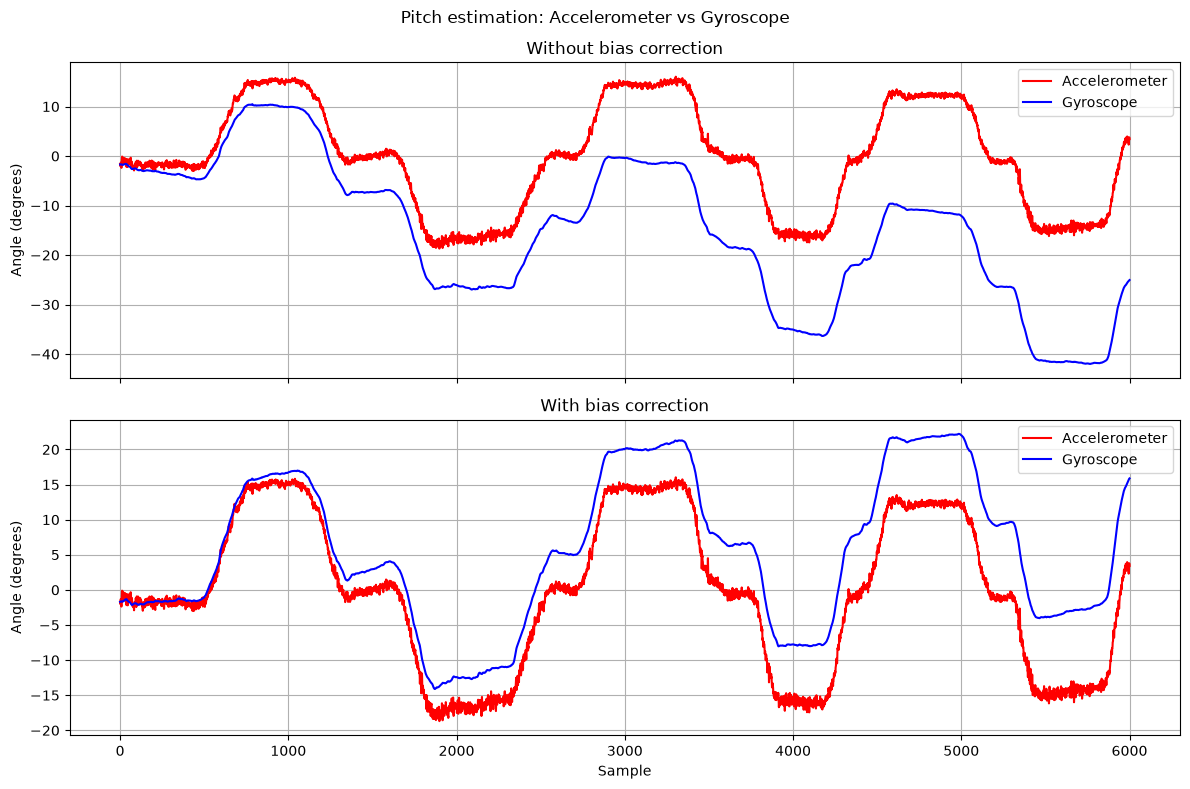

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Without bias correction
slow["angle_gyro"] = slow["angle_acc"].iloc[0] + (rate * slow["dt"]).cumsum()

# With bias correction
for i, corrected_rate in enumerate([rate, rate - bias]):
    slow["angle_gyro"] = (
        slow["angle_acc"].iloc[0]
        + (corrected_rate * slow["dt"].fillna(0)).cumsum()
    )

    ax[i].plot(slow["angle_acc"], color="r", label="Accelerometer")
    ax[i].plot(slow["angle_gyro"], color="b", label="Gyroscope")

    ax[i].set_title("Without bias correction" if i == 0 else "With bias correction")
    ax[i].set_ylabel("Angle (degrees)")
    ax[i].legend()
    ax[i].grid(True)

ax[1].set_xlabel("Sample")
fig.suptitle("Pitch estimation: Accelerometer vs Gyroscope")

plt.tight_layout()
plt.show()

In [16]:
def complementary(angle_acc, rate, dt, alpha):
    angle = np.zeros(len(angle_acc))
    angle[0] = angle_acc[0]
    for i in range(1, len(angle)):
        # predict with the gyro: previous angle + rate * dt
        prediction = angle[i-1] + rate[i]*dt[i]
        # correct towards the accelerometer:
        angle[i] = alpha*prediction + (1 - alpha) * angle_acc[i]
        # angle[i] = alpha * prediction + (1 - alpha) * angle_acc[i]
    return angle

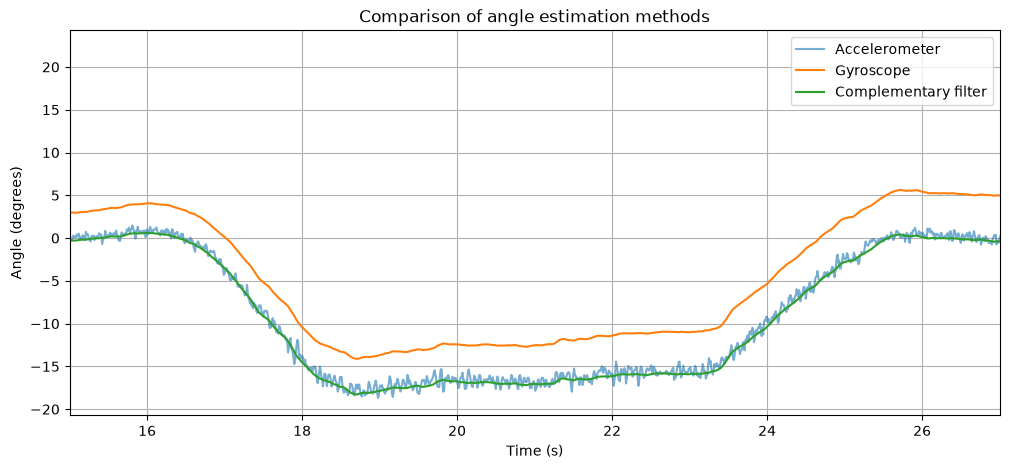

In [42]:
slow["angle_cf"] = complementary(
    slow["angle_acc"].to_numpy(),
    rate,
    slow["t"].diff().fillna(0).to_numpy(),
    0.98
)
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(slow["t"], slow["angle_acc"], label="Accelerometer", alpha=0.60)
ax.plot(slow["t"], slow["angle_gyro"], label="Gyroscope")
ax.plot(slow["t"], slow["angle_cf"], label="Complementary filter")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Angle (degrees)")
ax.set_title("Comparison of angle estimation methods")
ax.legend()
ax.grid(True)
ax.set_xlim(15, 27)
plt.show()

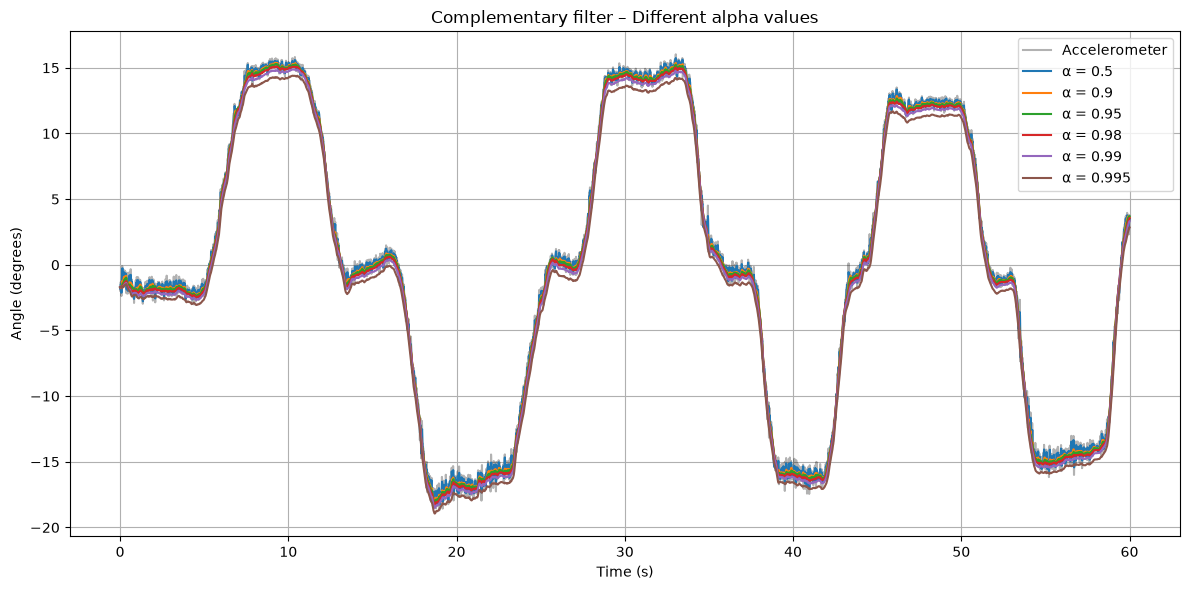

In [ ]:
alphas = [0.5, 0.9, 0.95, 0.98, 0.99, 0.995]

fig, ax = plt.subplots(figsize=(12, 6))

# Accelerometer reference
ax.plot(slow["t"], slow["angle_acc"],
        color="black", alpha=0.3, label="Accelerometer")

# Complementary filter for different alpha values
for alpha in alphas:
    angle_cf = complementary(
        slow["angle_acc"].to_numpy(),
        np.asarray(rate),
        slow["t"].diff().fillna(0).to_numpy(),
        alpha
    )

    ax.plot(slow["t"], angle_cf, label=f"α = {alpha}")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Angle (degrees)")
ax.set_title("Complementary filter – Different alpha values")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

## Now for the fast

In [48]:
fast["angle_acc"]  = np.degrees(np.arctan2(fast["ax"], np.sqrt(fast["ay"]**2 + fast["az"]**2)))
rate = -fast["gy"]
bias = rate[fast["t"] < 2].mean()

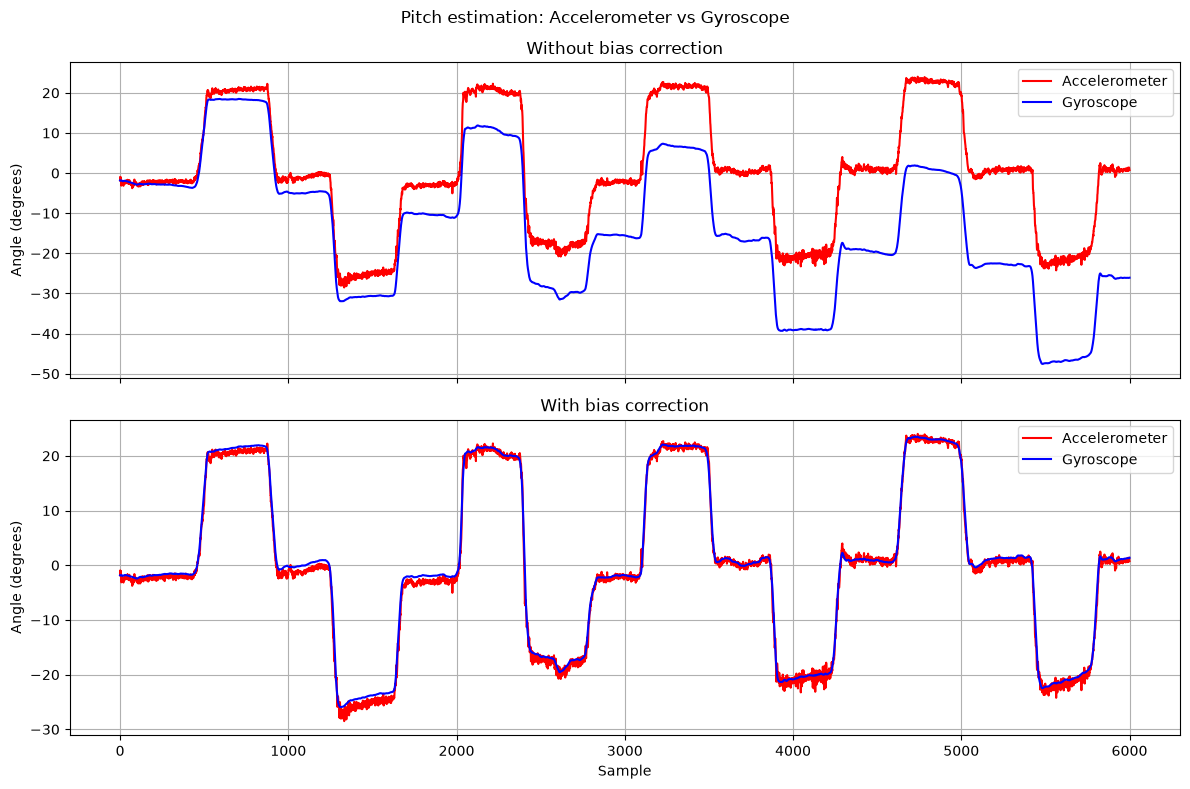

In [49]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Without bias correction
fast["angle_gyro"] = fast["angle_acc"].iloc[0] + (rate * fast["dt"]).cumsum()

# With bias correction
for i, corrected_rate in enumerate([rate, rate - bias]):
    fast["angle_gyro"] = (
        fast["angle_acc"].iloc[0]
        + (corrected_rate * fast["dt"].fillna(0)).cumsum()
    )

    ax[i].plot(fast["angle_acc"], color="r", label="Accelerometer")
    ax[i].plot(fast["angle_gyro"], color="b", label="Gyroscope")

    ax[i].set_title("Without bias correction" if i == 0 else "With bias correction")
    ax[i].set_ylabel("Angle (degrees)")
    ax[i].legend()
    ax[i].grid(True)

ax[1].set_xlabel("Sample")
fig.suptitle("Pitch estimation: Accelerometer vs Gyroscope")

plt.tight_layout()
plt.show()

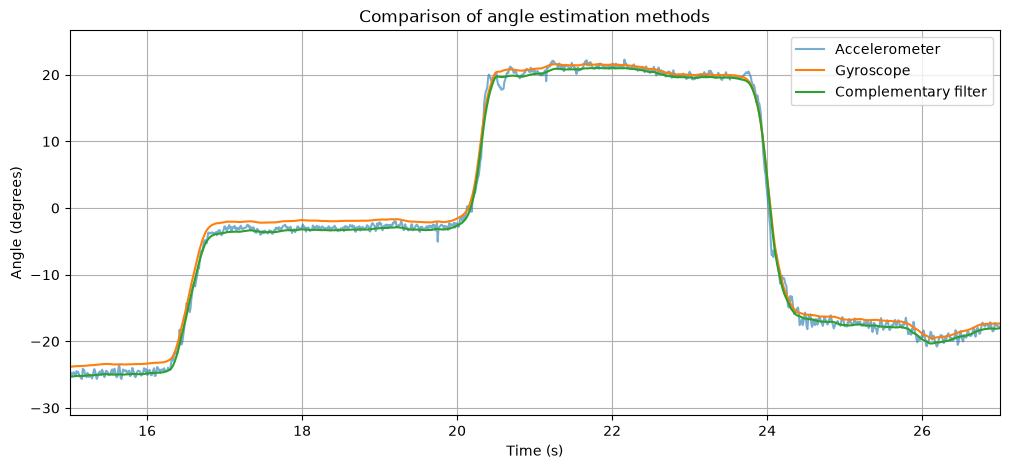

In [50]:
fast["angle_cf"] = complementary(
    fast["angle_acc"].to_numpy(),
    rate,
    fast["t"].diff().fillna(0).to_numpy(),
    0.98
)
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(fast["t"], fast["angle_acc"], label="Accelerometer", alpha=0.60)
ax.plot(fast["t"], fast["angle_gyro"], label="Gyroscope")
ax.plot(fast["t"], fast["angle_cf"], label="Complementary filter")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Angle (degrees)")
ax.set_title("Comparison of angle estimation methods")
ax.legend()
ax.grid(True)
ax.set_xlim(15, 27)
plt.show()

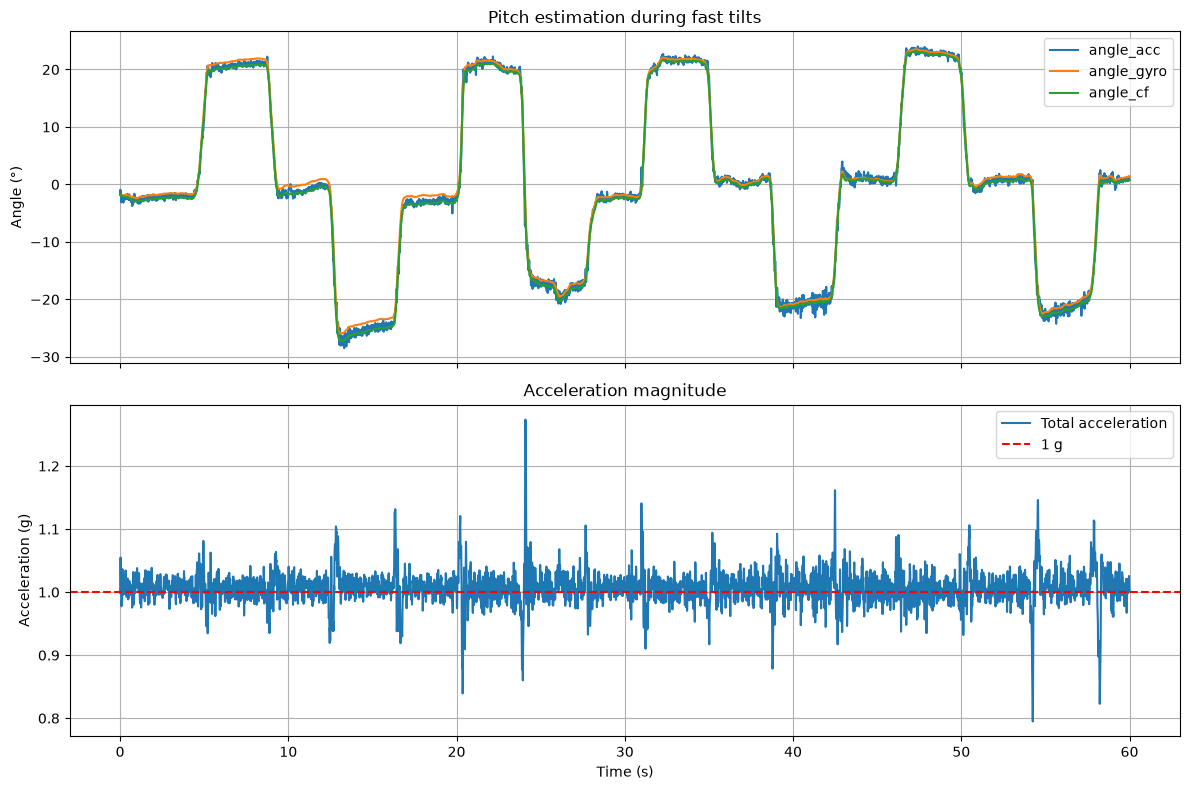

In [53]:
# Total acceleration magnitude
fast["acc_magnitude"] = np.sqrt(
    fast["ax"]**2 +
    fast["ay"]**2 +
    fast["az"]**2
)

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Angle comparison
for col in ["angle_acc", "angle_gyro", "angle_cf"]:
    ax[0].plot(fast["t"], fast[col], label=col)

ax[0].set_ylabel("Angle (°)")
ax[0].set_title("Pitch estimation during fast tilts")
ax[0].legend()
ax[0].grid(True)

# Acceleration magnitude
ax[1].plot(fast["t"], fast["acc_magnitude"], label="Total acceleration")
ax[1].axhline(1, color="r", linestyle="--", label="1 g")

ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Acceleration (g)")
ax[1].set_title("Acceleration magnitude")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

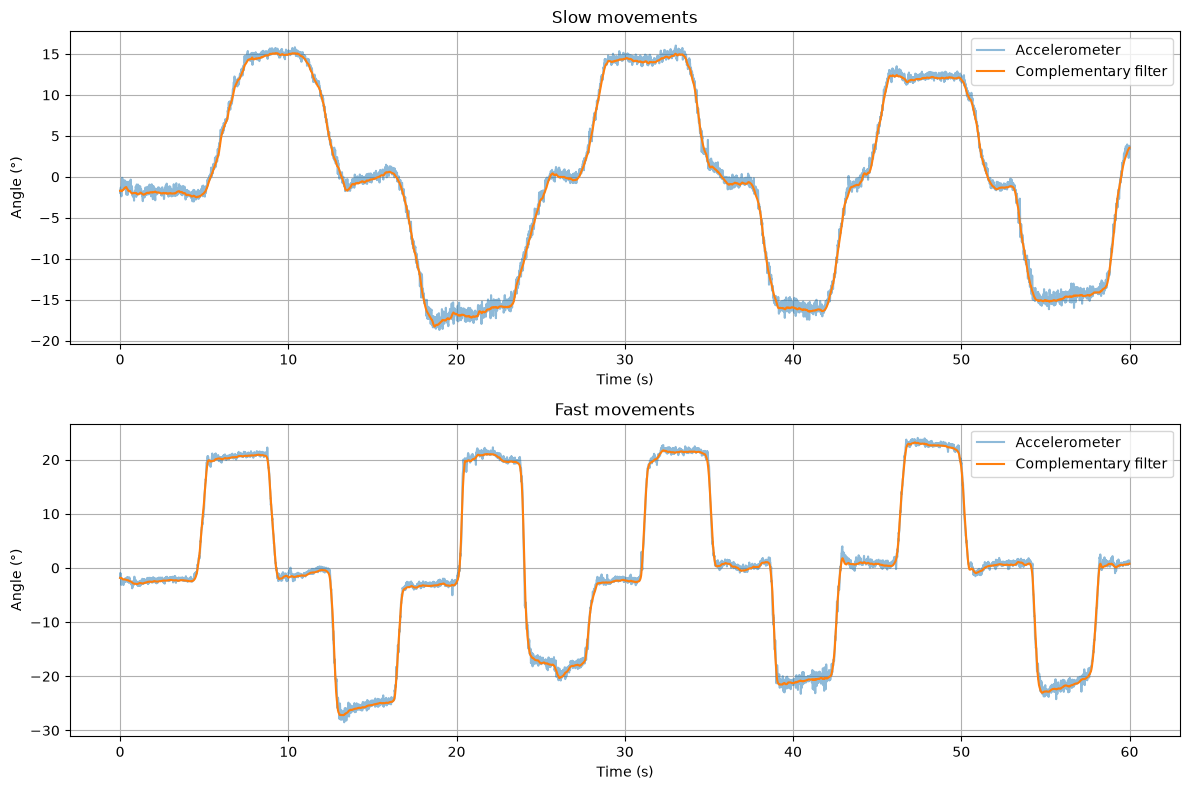

In [54]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

for axis, (name, df) in zip(ax, [("Slow", slow), ("Fast", fast)]):
    axis.plot(df["t"], df["angle_acc"], label="Accelerometer", alpha=0.5)
    axis.plot(df["t"], df["angle_cf"], label="Complementary filter")
    axis.set_title(f"{name} movements")
    axis.set_xlabel("Time (s)")
    axis.set_ylabel("Angle (°)")
    axis.legend()
    axis.grid(True)

plt.tight_layout()
plt.show()


## Complementary Filter – Results and Conclusions

### 1. Choice of Alpha

**Chosen α = 0.97**

At a sampling frequency of 100 Hz (dt ≈ 0.01 s), the approximate filter time constant is:

\[
\tau = -\frac{\Delta t}{\ln(\alpha)}
\approx 0.33 \text{ s}
\]

From Cell 9:

| Alpha | Noise (°) | Mean error (°) | MAE (°) |
|---|---:|---:|---:|
| 0.95 | 0.260 | -0.087 | 0.303 |
| 0.98 | 0.235 | -0.233 | 0.364 |

Alpha = 0.98 produced the lowest noise, while 0.95 resulted in a smaller mean error and MAE relative to the accelerometer.

I chose **α = 0.97** as a compromise between noise reduction and long-term correction of gyroscope drift.

The exact performance of α = 0.97 has not yet been quantified using the Cell 9 metrics.

### 2. Fast Tilt Experiment

The `fast` dataset was used to evaluate the complementary filter during rapid changes in orientation.

**Observations:**
- The complementary filter closely follows the accelerometer's overall angle trajectory.
- The filtered angle is smoother than the accelerometer estimate.
- Rapid changes in pitch are preserved without obvious large delays.
- The acceleration magnitude occasionally deviates significantly from 1 g, indicating additional acceleration or disturbances during movement.

These results suggest that the complementary filter reduces measurement noise while maintaining a fast response.

However, without an independent reference angle, the true estimation error cannot be determined.

### 3. Gyroscope Sign Convention

For the chosen accelerometer angle definition, the gyroscope rate must be:

\[
\omega = -g_y
\]

The gyroscope's positive Y-axis rotation has the opposite sign to the positive angle defined by the accelerometer.

Therefore, the complementary filter must integrate the negative Y-axis gyroscope rate, with bias correction applied consistently.

**Important:** The ESP32-C6 firmware must use exactly the same sign convention as the Python implementation to ensure correct angle estimation.

### Conclusion

A complementary filter with α = 0.97 appears to provide a reasonable balance between noise reduction, gyroscope drift correction, and responsiveness during rapid movements.

Further testing with a known reference angle would be necessary to verify accuracy and optimize α before implementing the balancing controller.
